<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/Full_Chip_Example_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Six-Qubit Full Chip

The chip uses four native `TransmonPocket6` qubits, two native `TransmonCrossFL` qubits, and a native `TunableCoupler01` between the two cross qubits. Five passive `RouteMeander` buses connect `Q_Main` to `Q1` through `Q5` in a planar star. The northern lateral pads end in native open terminations, which leave continuous ground between the buses without airbridges.

Readout uses six native `CoupledLineTee` components and four two-port feedlines, whereby the northern feedline serves `Q3`, `Q4`, and `Q5` together. The other three feedlines serve `Q_Main`, `Q1`, and `Q2` individually, which leaves clear paths for the three flux lines and the tunable-coupler microwave drive. Every launcher follows its chip edge with the outer metal 100 µm inside the footprint.

## Layout parameters

| Parameter | Value or Quantum Metal option |
| --- | --- |
| Chip controls | `CHIP_SIZE_X="11mm"`, `CHIP_SIZE_Y="9mm"`; larger footprints move the launchers and series capacitors outward |
| Central qubit | `Q_Main`: (0, −1) mm, `TransmonPocket6`, 425 µm island width, 650 µm pocket height |
| Cross qubits | `Q1`: (−2.75, −1.8) mm, 0°; `Q2`: (−2.75, −1.2) mm, 180°; 95 µm bus claws |
| Tunable coupler | `TunableCoupler01`: (−2.81, −1.5) mm, 90°, 500 µm coupling width |
| Northern qubits | `Q3`: (−3, 0.5) mm; `Q4`: (0, 1) mm; `Q5`: (3, 0.5) mm; 455 µm islands, 650 µm pockets |
| Pocket analysis metadata | `Q_Main`: 13 nH; `Q3` and `Q4`: 14 nH; `Q5`: 15 nH |
| Main bus connection pads | 60 µm width and 10 µm island gap for buses 01, 02, 04, 05; 90 µm width and 30 µm gap for bus 03 |
| Northern bus connection pads | 80 µm width, 15 µm island gap |
| Pocket readout pads | 80 µm width, 50 µm island gap |
| Passive bus targets | Main–Q1: 6.0 mm; Main–Q2: 6.4 mm; Main–Q3: 6.8 mm; Main–Q4: 7.2 mm; Main–Q5: 7.5 mm |
| Readout length targets | Main: 5.6 mm; Q1: 6.8 mm; Q2: 5.4 mm; Q3: 5.0 mm; Q4: 5.8 mm; Q5: 5.4 mm |
| Readout length convention | Meander plus the filleted secondary arm of its coupled-line tee |
| Bus and readout CPW | Coplanar waveguide: 10 µm center trace, 6 µm slots, 99 µm bend radius |
| Meander spacing | 200–250 µm for buses; 250 µm for readouts |
| Coupled-line tees | 200 µm coupled length, 150 µm exit leg, 50 µm bend radius, shorted secondary termination |
| Coupler metal-edge spacing | 15.1 µm: 5.1 µm primary slot + 4 µm ground strip + 6 µm secondary slot |
| Feedlines | 11.7 µm trace, 5.1 µm slots; 70 µm bends |
| Flux lines | 5 µm trace, 3 µm slots, 50 µm bends; one line to each cross qubit and one to the tunable coupler |
| Tunable-coupler drive | Direct 10/6 µm CPW from its own left-edge launcher to the `Control` pin |
| Series capacitor control | `INLINE_CAPACITORS=True`; `False` connects the feedline directly to its launcher |
| Inline series component | Native two-terminal `CapNInterdigital`; its two pins interrupt the center-conductor path |
| Series capacitor geometry | Five 20 µm fingers, 10 µm width, 6 µm gaps, 50 µm leads; one near each readout launcher |
| Launcher geometry | 160 µm width, 200 µm body, 200 µm taper, 25 µm lead, 58 µm ground gap |
| Ground cheesing | Native 25 × 25 µm square holes on a 100 µm grid |
| Component keep-out control | `CHEESE_KEEPOUT="50um"` uses native `no_cheese.buffer` |
| Chip-edge cheese clearance | Native `edge_nocheese="112.5um"` puts each 25 µm hole edge at least 100 µm inside the chip |
| GDS layer 1 | Positive ground, capacitor islands, CPW circuit, and launcher electrodes |
| GDS layer 9 | Seven symbolic lumped-junction markers; process-specific junction electrodes require their own mask geometry |
| GDS precision | 1 nm; one top-level cell |

The source's final bus lengths and pocket inductance metadata set the geometry and analysis labels. The centerline length of each readout includes the native tee arm and its circular bend, while an electromagnetic model supplies loaded frequencies and coupling rates. A direct microwave control line addresses the tunable coupler, and the five qubit buses remain passive.

$$
\ell_{\mathrm{readout}}=\ell_{\mathrm{meander}}+\ell_{\mathrm{tee}},\qquad \ell_{\mathrm{tee}}=\ell_{\mathrm{raw}}-\left(2-\frac{\pi}{2}\right)r_f.
$$

Here $\ell_{\mathrm{raw}}$ denotes the tee arm's unrounded centerline and $r_f=50$ µm denotes its bend radius. The relation applies to the tee's single right-angle bend, with lengths expressed in millimeters in the code. Native routing checks require each interior right-angle segment to hold two adjacent fillet radii.

## Quantum Metal documentation

[TransmonPocket6](https://qiskit-community.github.io/qiskit-metal/_modules/qiskit_metal/qlibrary/qubits/transmon_pocket_6.html) · [TransmonCrossFL](https://qiskit-community.github.io/qiskit-metal/_modules/qiskit_metal/qlibrary/qubits/transmon_cross_fl.html) · [TunableCoupler01](https://qiskit-community.github.io/qiskit-metal/_modules/qiskit_metal/qlibrary/couplers/tunable_coupler_01.html) · [CoupledLineTee](https://qiskit-community.github.io/qiskit-metal/_modules/qiskit_metal/qlibrary/couplers/coupled_line_tee.html) · [Two-terminal series capacitor](https://qiskit-community.github.io/qiskit-metal/_modules/qiskit_metal/qlibrary/lumped/cap_n_interdigital.html) · [RouteMeander](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.12-Simple-Meander.html) · [Native design rules](https://qiskit-community.github.io/qiskit-metal/tut/2-From-components-to-chip/2.24-Design-rule-checking.html) · [Native cheesing and GDS export](https://qiskit-community.github.io/qiskit-metal/tut/3-Renderers/3.2-Export-your-design-to-GDS.html)


In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [2]:
"""This script builds a six-qubit full chip in Quantum Metal."""

# --- Control Knobs ---
CHIP_SIZE_X = "11mm"
CHIP_SIZE_Y = "9mm"
CHEESE_KEEPOUT = "50um"
INLINE_CAPACITORS = True
OUTPUT_FILENAME = "Full_Chip_Quantum_Metal.gds"

# --- Imports and Design ---
import logging
import os
import warnings
from importlib.metadata import version
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

import gdstk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit_metal as qm
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.couplers.tunable_coupler_01 import TunableCoupler01
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.qubits.transmon_pocket_6 import TransmonPocket6
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from qiskit_metal.validation import DEFAULT_RULES, SHAPE_RULES, validate

plt.rcParams["figure.dpi"] = 250
qm.logger.setLevel(logging.WARNING)
warnings.filterwarnings(
    "ignore",
    message=(r"The behavior of DataFrame concatenation "
             r"with empty or all-NA entries is deprecated\."),
    category=FutureWarning,
    module=(r"qiskit_metal\.(?:qgeometries\.qgeometries_handler|"
            r"renderers\.renderer_gds\.gds_renderer)$"),
)

design = designs.DesignPlanar(overwrite_enabled=True, enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
design.variables.cpw_width = "10um"
design.variables.cpw_gap = "6um"
chip_x = float(design.parse_value(CHIP_SIZE_X))
chip_y = float(design.parse_value(CHIP_SIZE_Y))
assert chip_x >= 11 and chip_y >= 9, "Use at least an 11 mm by 9 mm footprint."
gds_renderer = QGDSRenderer(design)
design.renderers.gds = gds_renderer
qubits, couplers = {}, {}
buses, resonators, feedlines, controls, launchpads, end_caps = [], [], [], [], [], []
length_records = []
print(f"Quantum Metal {version('quantum-metal')}")

Quantum Metal 0.9.0


In [3]:
# --- Central Pocket Qubit ---
qubits["Main"] = TransmonPocket6(
    design, "Q_Main",
    options=Dict(
        pos_x="0mm", pos_y="-1mm", layer="1",
        pad_width="425um", pocket_height="650um",
        hfss_inductance="13nH", aedt_hfss_inductance="13nH",
        connection_pads=Dict(
            readout=Dict(loc_W=0, loc_H=-1, pad_width="80um", pad_gap="50um"),
            bus_01=Dict(loc_W=-1, loc_H=-1, pad_width="60um", pad_gap="10um"),
            bus_02=Dict(loc_W=-1, loc_H=1, pad_width="60um", pad_gap="10um"),
            bus_03=Dict(loc_W=0, loc_H=1, pad_width="90um", pad_gap="30um"),
            bus_04=Dict(loc_W=1, loc_H=1, pad_width="60um", pad_gap="10um"),
            bus_05=Dict(loc_W=1, loc_H=-1, pad_width="60um", pad_gap="10um"),
        ),
    ),
)

# --- Flux-Controlled Cross Qubits and Tunable Coupler ---
for name, y, angle, bus_pin, bus_side, readout_side in (
    ("Q1", -1.8, 0, "bus_01", 180, 0),
    ("Q2", -1.2, 180, "bus_02", 0, 180),
):
    qubits[name] = TransmonCrossFL(
        design, name,
        options=Dict(
            pos_x="-2.75mm", pos_y=f"{y}mm", orientation=str(angle), layer="1",
            connection_pads=Dict({
                bus_pin: Dict(connector_location=str(bus_side), claw_length="95um"),
                "readout": Dict(connector_location=str(readout_side)),
            }),
            fl_options=Dict(),
        ),
    )
tunable_coupler = TunableCoupler01(
    design, "Tune_C_Q12",
    options=Dict(pos_x="-2.81mm", pos_y="-1.5mm", orientation="90",
                 c_width="500um", layer="1"),
)

# --- Northern Pocket Qubits ---
for name, x, y, bus_pin, inductance, side_pads in (
    ("Q3", -3, 0.5, "bus_03", "14nH", {"bus_q3_q4": 1}),
    ("Q4", 0, 1.0, "bus_04", "14nH", {"bus_q3_q4": -1, "bus_q4_q5": 1}),
    ("Q5", 3, 0.5, "bus_05", "15nH", {"bus_q4_q5": -1}),
):
    pads = Dict({
        bus_pin: Dict(loc_W=0, loc_H=-1, pad_width="80um", pad_gap="15um"),
        "readout": Dict(loc_W=0, loc_H=1, pad_width="80um", pad_gap="50um"),
    })
    for pin, side in side_pads.items():
        pads[pin] = Dict(loc_W=side, loc_H=-1, pad_width="80um", pad_gap="15um")
    qubits[name] = TransmonPocket6(
        design, name,
        options=Dict(
            pos_x=f"{x}mm", pos_y=f"{y}mm", layer="1",
            hfss_inductance=inductance, aedt_hfss_inductance=inductance,
            connection_pads=pads,
        ),
    )

# --- Open Unused Lateral Pads ---
for name, pin_name in (
    ("Q3", "bus_q3_q4"), ("Q4", "bus_q3_q4"),
    ("Q4", "bus_q4_q5"), ("Q5", "bus_q4_q5"),
):
    pin = qubits[name].pins[pin_name]
    angle = np.degrees(np.arctan2(pin.normal[1], pin.normal[0]))
    termination = OpenToGround(
        design, f"Open_{name}_{pin_name}",
        options=Dict(pos_x=f"{pin.middle[0]}mm", pos_y=f"{pin.middle[1]}mm",
                     orientation=str(angle), layer="1", width="10um", gap="6um"),
    )
    design.connect_pins(qubits[name].id, pin_name, termination.id, "open")

In [4]:
# --- Passive Central Buses ---
for tag, target, start_lead, end_lead, spacing, asymmetry, start_jogs, end_jogs in (
    ("01", 6.0, 0.125, 0.225, 0.250, 1.305, {}, {}),
    ("02", 6.4, 0.325, 0.125, 0.200, 0.450, {}, {}),
    ("03", 6.8, 0.225, 0.125, 0.200, 0.050, {}, {}),
    ("04", 7.2, 0.575, 0.250, 0.200, -0.250,
     {0: ("L", "250um")}, {0: ("L", "1mm"), 1: ("R", "250um")}),
    ("05", 7.5, 0.225, 0.125, 0.200, -0.600, {}, {}),
):
    bus_pin = f"bus_{tag}"
    bus = RouteMeander(
        design, f"Bus_{tag}",
        options=Dict(
            layer="1", trace_width="10um", trace_gap="6um", fillet="99um",
            total_length=f"{target}mm", prevent_short_edges="true",
            pin_inputs=Dict(
                start_pin=Dict(component="Q_Main", pin=bus_pin),
                end_pin=Dict(component=f"Q{int(tag)}", pin=bus_pin),
            ),
            lead=Dict(
                start_straight=f"{start_lead}mm", end_straight=f"{end_lead}mm",
                start_jogged_extension=Dict(start_jogs),
                end_jogged_extension=Dict(end_jogs),
            ),
            meander=Dict(spacing=f"{spacing}mm", asymmetry=f"{asymmetry}mm"),
        ),
    )
    if abs(bus.length - target) > 1e-8:
        bus.options.total_length = f"{float(bus.p.total_length) + target - bus.length}mm"
        bus.rebuild()
    buses.append(bus)
    length_records.append({"component": bus.name, "target_mm": target,
                           "actual_mm": bus.length})

# --- Coupled-Line Readout Resonators ---
for name, x, y, angle, target, start_lead, end_lead, spacing, asymmetry, start_jogs, end_jogs in (
    ("Main", 2, -3.5, 180, 5.6, 0.900, 0.625, 0.250, 0.050,
     {0: ("L", "250um")}, {0: ("L", "600um")}),
    ("Q1", -2, -3.5, 180, 6.8, 0.725, 0.500, 0.250, 0.000,
     {0: ("L", "800um")}, {}),
    ("Q2", -4.5, 0, 90, 5.4, 0.350, 0.150, 0.250, 0.450, {}, {}),
    ("Q3", -3, 3, 0, 5.0, 0.150, 0.150, 0.250, 0.000, {}, {}),
    ("Q4", 0, 3, 0, 5.8, 0.150, 0.150, 0.250, 0.000, {}, {}),
    ("Q5", 3, 3, 0, 5.4, 0.150, 0.150, 0.250, 0.000, {}, {}),
):
    tee = CoupledLineTee(
        design, f"CLT_{name}",
        options=Dict(
            pos_x=f"{x}mm", pos_y=f"{y}mm", orientation=str(angle), layer="1",
            prime_width="11.7um", prime_gap="5.1um",
            second_width="10um", second_gap="6um",
            coupling_length="200um", coupling_space="4um",
            down_length="150um", fillet="50um", open_termination=False,
        ),
    )
    secondary = tee.qgeometry_table("path")
    secondary = secondary[secondary.name == "second_cpw"].iloc[0]
    arm_length = secondary.geometry.length - (2 - np.pi / 2) * secondary.fillet
    resonator = RouteMeander(
        design, f"Readout_{name}",
        options=Dict(
            layer="1", trace_width="10um", trace_gap="6um", fillet="99um",
            total_length=f"{target - arm_length}mm", prevent_short_edges="true",
            pin_inputs=Dict(
                start_pin=Dict(component=qubits[name].name, pin="readout"),
                end_pin=Dict(component=tee.name, pin="second_end"),
            ),
            lead=Dict(
                start_straight=f"{start_lead}mm", end_straight=f"{end_lead}mm",
                start_jogged_extension=Dict(start_jogs),
                end_jogged_extension=Dict(end_jogs),
            ),
            meander=Dict(spacing=f"{spacing}mm", asymmetry=f"{asymmetry}mm"),
        ),
    )
    if abs(resonator.length + arm_length - target) > 1e-8:
        resonator.options.total_length = (
            f"{float(resonator.p.total_length) + target - arm_length - resonator.length}mm"
        )
        resonator.rebuild()
    couplers[name] = tee
    resonators.append(resonator)
    length_records.append({"component": resonator.name, "target_mm": target,
                           "actual_mm": resonator.length + arm_length})

In [5]:
# --- Readout Feedlines and Perimeter Ports ---
for group, tag, edge, coordinate, tee_pin in (
    ("Main", "L", "bottom", 1.4, "prime_end"),
    ("Main", "R", "bottom", 2.6, "prime_start"),
    ("Q1", "L", "bottom", -2.6, "prime_end"),
    ("Q1", "R", "bottom", -1.4, "prime_start"),
    ("Q2", "L", "left", -0.6, "prime_start"),
    ("Q2", "R", "left", 0.6, "prime_end"),
    ("Q3", "L", "left", 3.0, "prime_start"),
    ("Q5", "R", "right", 3.0, "prime_end"),
):
    name = f"{group}_{tag}"
    if edge == "bottom":
        px, py, angle = coordinate, -chip_y / 2 + 0.500, 90
        cx, cy, cap_angle = px, py + 0.300, 0
    elif edge == "left":
        px, py, angle = -chip_x / 2 + 0.500, coordinate, 0
        cx, cy, cap_angle = px + 0.300, py, -90
    else:
        px, py, angle = chip_x / 2 - 0.500, coordinate, 180
        cx, cy, cap_angle = px - 0.300, py, 90
    pad = LaunchpadWirebond(
        design, f"Pad_{name}",
        options=Dict(
            pos_x=f"{px}mm", pos_y=f"{py}mm", orientation=str(angle), layer="1",
            trace_width="11.7um", trace_gap="5.1um", lead_length="25um",
            pad_width="160um", pad_height="200um", taper_height="200um", pad_gap="58um",
        ),
    )
    launchpads.append(pad)
    port, port_pin = pad, "tie"
    if INLINE_CAPACITORS:
        cap = CapNInterdigital(
            design, f"FeedCap_{name}",
            options=Dict(
                pos_x=f"{cx}mm", pos_y=f"{cy}mm", orientation=str(cap_angle), layer="1",
                north_width="11.7um", north_gap="5.1um",
                south_width="11.7um", south_gap="5.1um",
                cap_width="10um", cap_gap="6um", cap_gap_ground="6um",
                finger_length="20um", finger_count="5", cap_distance="50um",
            ),
        )
        end_caps.append(cap)
        feedlines.append(RouteStraight(
            design, f"Port_{name}",
            options=Dict(
                layer="1", trace_width="11.7um", trace_gap="5.1um",
                pin_inputs=Dict(start_pin=Dict(component=pad.name, pin="tie"),
                                end_pin=Dict(component=cap.name, pin="south_end")),
            ),
        ))
        port, port_pin = cap, "north_end"
    tee = couplers[group]
    anchors = Dict()
    if edge == "bottom":
        anchors[0] = np.array([px, tee.p.pos_y])
    elif group == "Q2":
        anchors[0] = np.array([tee.p.pos_x, py])
    route_type = RouteAnchors if anchors else RouteStraight
    feedlines.append(route_type(
        design, f"Feed_{name}",
        options=Dict(
            layer="1", trace_width="11.7um", trace_gap="5.1um", fillet="70um",
            anchors=anchors,
            pin_inputs=Dict(start_pin=Dict(component=port.name, pin=port_pin),
                            end_pin=Dict(component=tee.name, pin=tee_pin)),
        ),
    ))
for left, right in (("Q3", "Q4"), ("Q4", "Q5")):
    feedlines.append(RouteStraight(
        design, f"Feed_{left}_{right}",
        options=Dict(
            layer="1", trace_width="11.7um", trace_gap="5.1um",
            pin_inputs=Dict(start_pin=Dict(component=couplers[left].name, pin="prime_end"),
                            end_pin=Dict(component=couplers[right].name, pin="prime_start")),
        ),
    ))

# --- Tunable-Coupler Drive and Three Flux Lines ---
for name, component, pin, edge, coordinate, anchors, width, gap in (
    ("Drive_TC", "Tune_C_Q12", "Control", "left", -1.452, {}, "10um", "6um"),
    ("Flux_TC", "Tune_C_Q12", "Flux", "bottom", -4.0,
     {0: (-4.0, -1.644)}, "5um", "3um"),
    ("Flux_Q1", "Q1", "flux_line", "bottom", 0.0,
     {0: (-2.75, -2.2), 1: (-1.95, -2.2), 2: (-1.95, -3.2), 3: (0.0, -3.2)},
     "5um", "3um"),
    ("Flux_Q2", "Q2", "flux_line", "left", 1.6,
     {0: (-2.75, -0.75), 1: (-3.45, -0.75), 2: (-3.45, 1.6)}, "5um", "3um"),
):
    px, py, angle = ((-chip_x / 2 + 0.500, coordinate, 0) if edge == "left"
                     else (coordinate, -chip_y / 2 + 0.500, 90))
    pad = LaunchpadWirebond(
        design, f"Pad_{name}",
        options=Dict(
            pos_x=f"{px}mm", pos_y=f"{py}mm", orientation=str(angle), layer="1",
            trace_width=width, trace_gap=gap, lead_length="25um",
            pad_width="160um", pad_height="200um", taper_height="200um", pad_gap="58um",
        ),
    )
    launchpads.append(pad)
    route_type = RouteAnchors if anchors else RouteStraight
    controls.append(route_type(
        design, name,
        options=Dict(
            layer="1", trace_width=width, trace_gap=gap, fillet="50um",
            anchors=Dict({key: np.array(point) for key, point in anchors.items()}),
            pin_inputs=Dict(start_pin=Dict(component=component, pin=pin),
                            end_pin=Dict(component=pad.name, pin="tie")),
        ),
    ))

In [6]:
# --- Symbolic Junction Markers ---
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
for _, junction in junction_table.iterrows():
    owner = design._components[int(junction.component)]
    owner.add_qgeometry(
        "poly", {"junction_marker": junction.geometry.buffer(
            float(junction.width) / 2, cap_style=2,
        )}, layer=9,
    )

# --- Native Routing and Geometry Checks ---
drc = validate(design, rules=[*DEFAULT_RULES, *SHAPE_RULES])
print(drc.report())
drc.raise_if_errors()
length_table = pd.DataFrame(length_records)
assert (length_table.actual_mm - length_table.target_mm).abs().max() < 1e-6
for route in buses + resonators + feedlines + controls:
    lengths = np.linalg.norm(np.diff(route.get_points(), axis=0), axis=1)
    radius = float(route.p.fillet)
    if radius > 0:
        assert np.min(lengths[[0, -1]]) >= radius - 1e-9, route.name
        assert len(lengths) <= 2 or np.min(lengths[1:-1]) >= 2 * radius - 1e-9, route.name
for pad in launchpads:
    metal = pad.qgeometry_table("poly")
    xmin, ymin, xmax, ymax = metal[~metal["subtract"]].geometry.union_all().bounds
    edge_distance = min(xmin + chip_x / 2, ymin + chip_y / 2,
                        chip_x / 2 - xmax, chip_y / 2 - ymax)
    assert np.isclose(edge_distance, 0.100, atol=1e-6), pad.name
display(length_table)
print(f"{len(qubits)} qubits; {len(buses)} passive quantum buses; "
      f"{len(resonators)} readouts; 4 feedlines; {len(launchpads)} perimeter launchers")

Design rules passed (12 rules ran, no findings).


,component,target_mm,actual_mm
0,Bus_01,6.0,6.0
1,Bus_02,6.4,6.4
2,Bus_03,6.8,6.8
3,Bus_04,7.2,7.2
4,Bus_05,7.5,7.5
5,Readout_Main,5.6,5.6
6,Readout_Q1,6.8,6.8
7,Readout_Q2,5.4,5.4
8,Readout_Q3,5.0,5.0
9,Readout_Q4,5.8,5.8


6 qubits; 5 passive quantum buses; 6 readouts; 4 feedlines; 12 perimeter launchers


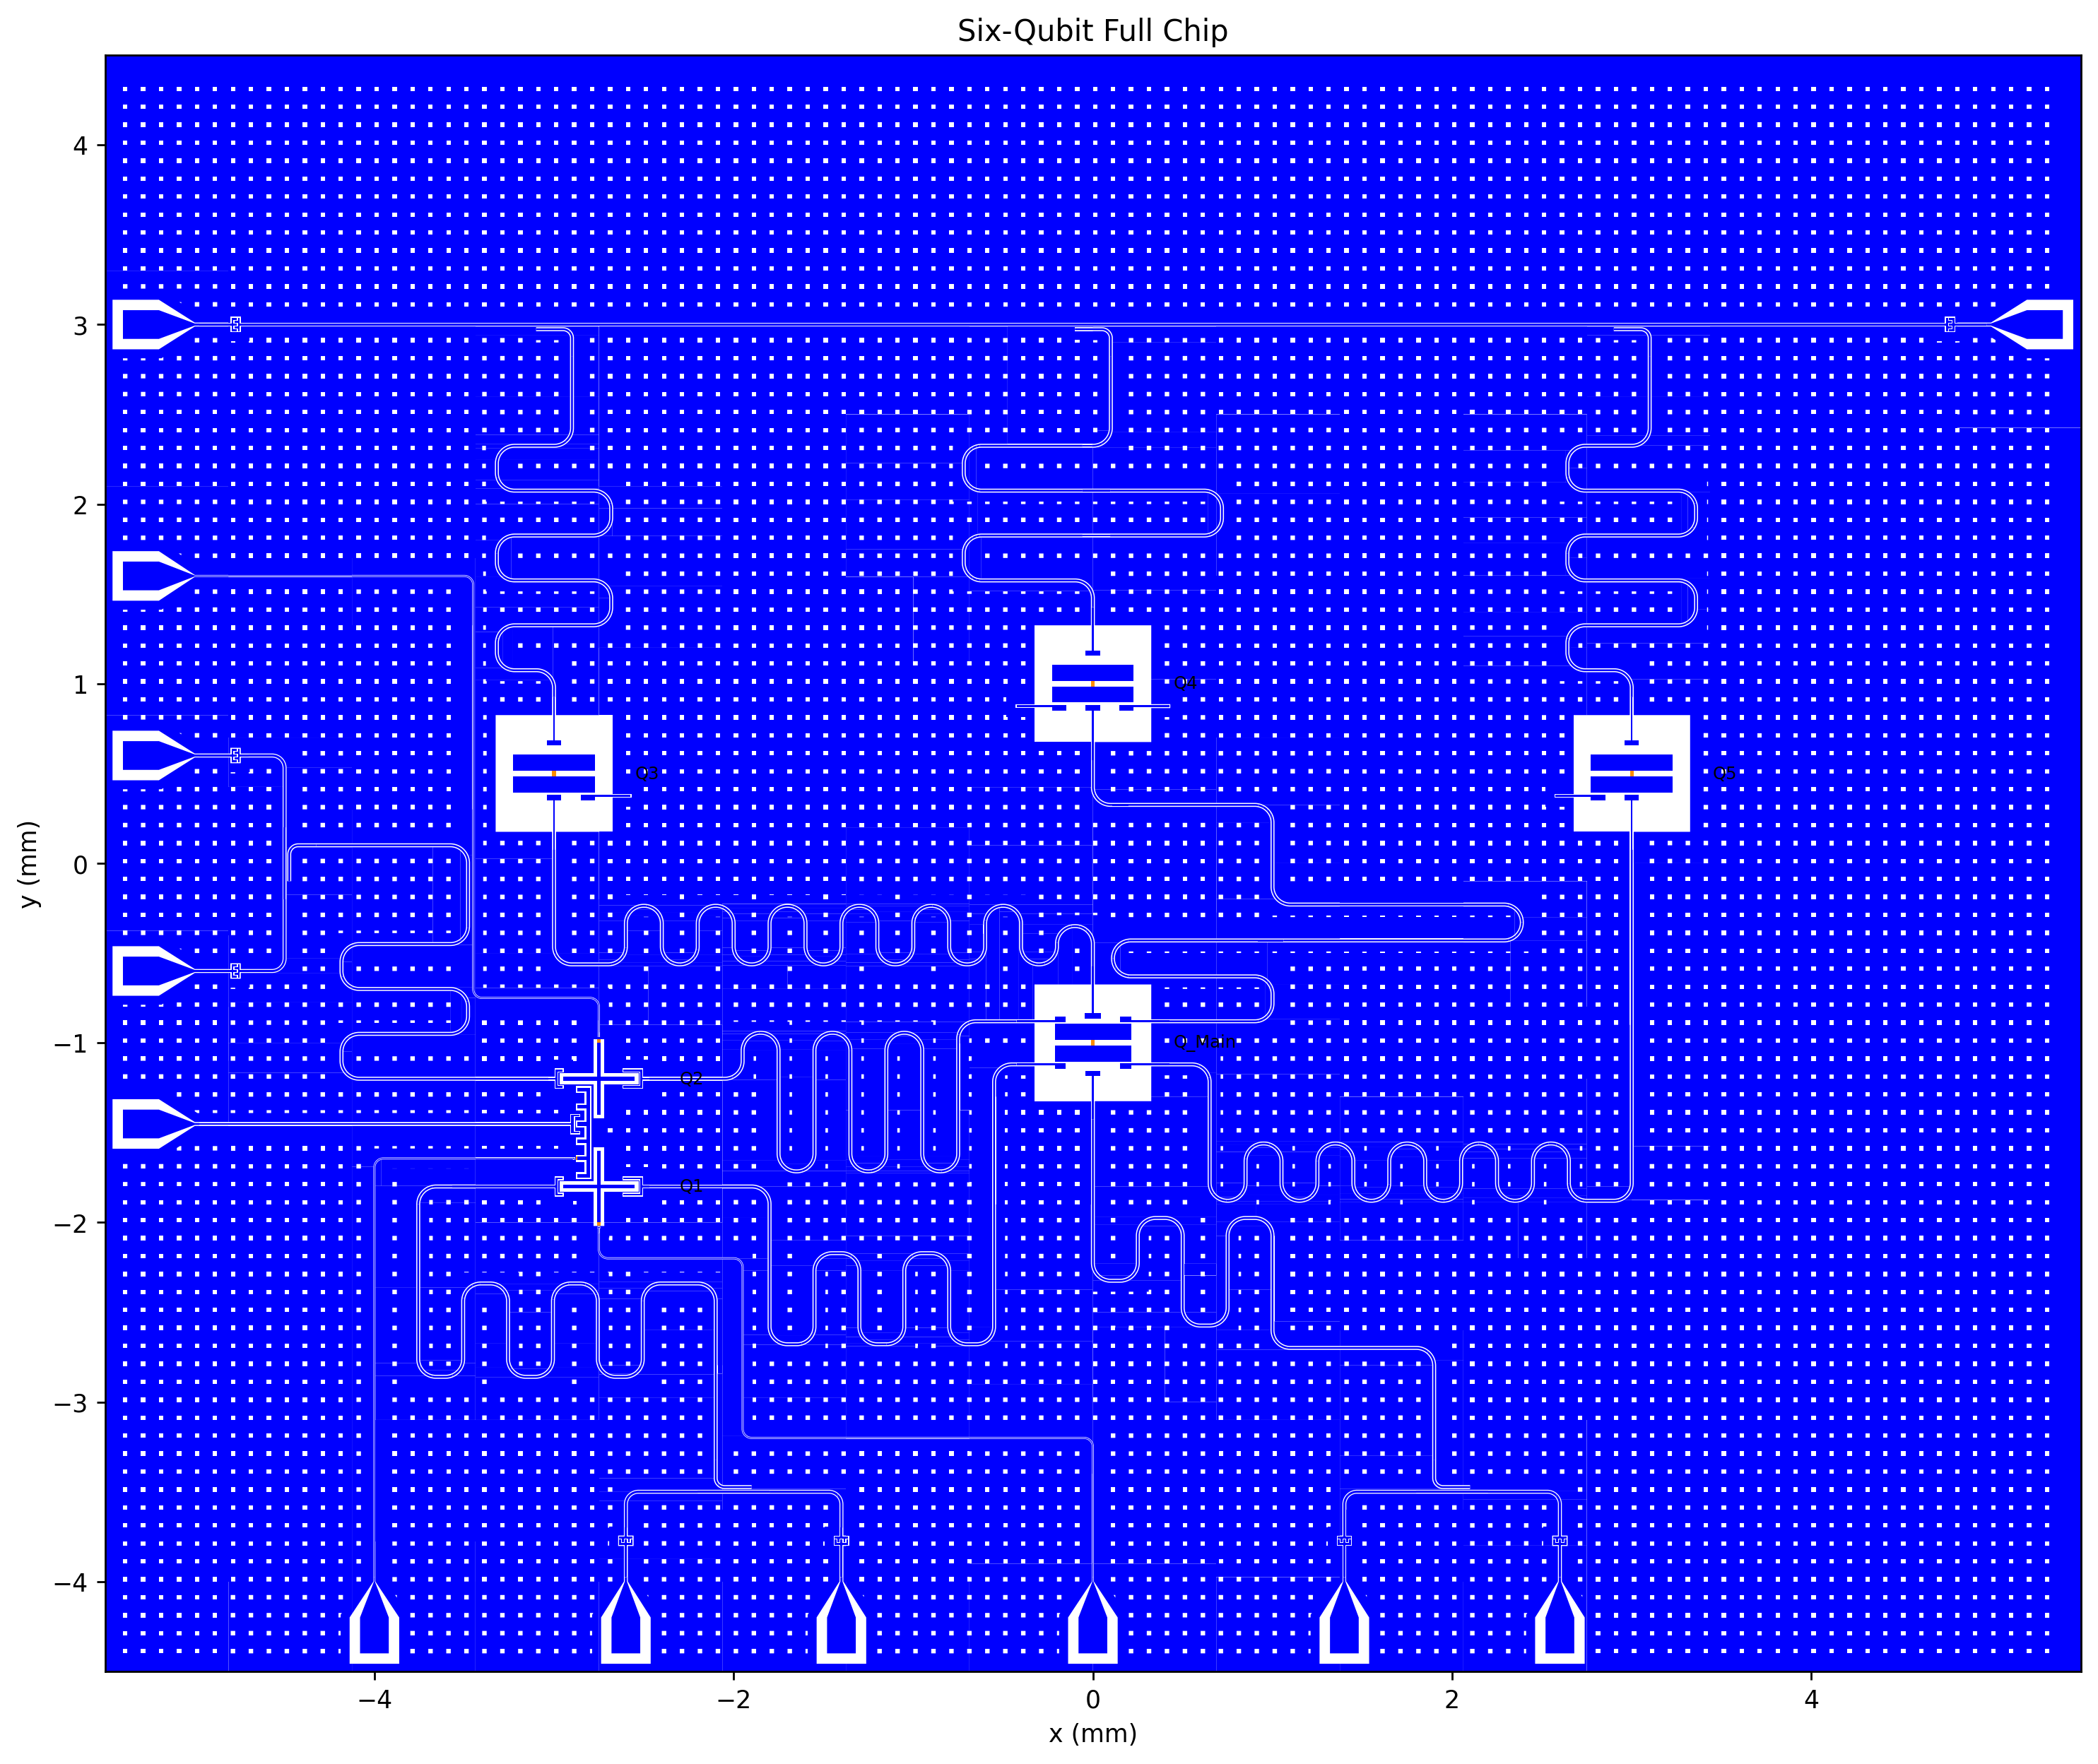

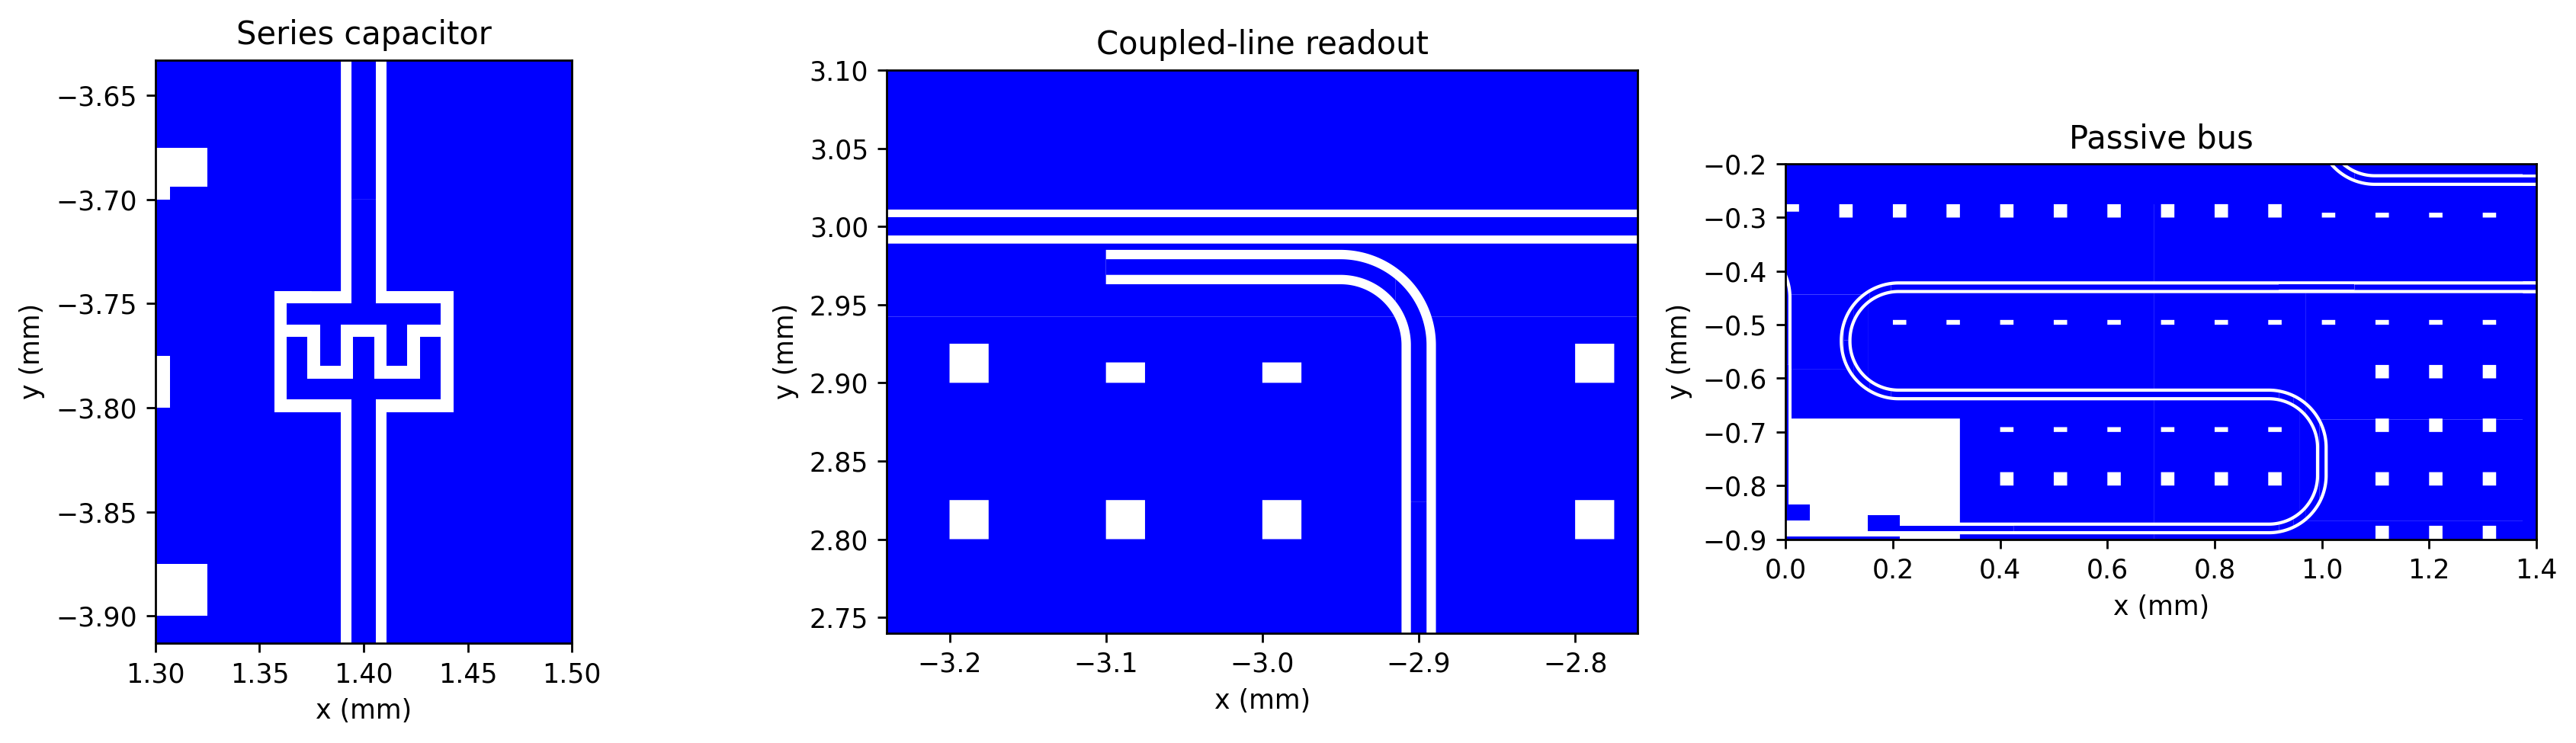

GDSII: Full_Chip_Quantum_Metal.gds (1,386,330 bytes)
Layers: 1 = positive ground/circuit; 9 = symbolic junction markers


/content/Full_Chip_Quantum_Metal.gds

In [7]:
# --- Native Cheesing and GDS Export ---
out = Path.cwd() / OUTPUT_FILENAME
gds_renderer.options.precision = "1e-9"
gds_renderer.options.tolerance = "1e-6"
gds_renderer.options.fabricate = "True"
gds_renderer.options.short_segments_to_not_fillet = "False"
gds_renderer.options.path_filename = ""
gds_renderer.options.cheese = QGDSRenderer.default_options.cheese.copy()
gds_renderer.options.no_cheese = QGDSRenderer.default_options.no_cheese.copy()
gds_renderer.options.no_cheese.buffer = CHEESE_KEEPOUT
gds_renderer.options.cheese.edge_nocheese = "112.5um"
gds_renderer.options.cheese.view_in_file = Dict(main={1: True, 9: False})
gds_renderer.options.no_cheese.view_in_file = Dict(main={1: False, 9: False})

# Export marker polygons while keeping the lumped-junction analysis sheets.
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    export_status = gds_renderer.export_to_gds(str(out))
finally:
    qm.logger.setLevel(previous_log_level)
    design.qgeometry.tables["junction"] = junction_table
assert export_status and out.is_file() and out.stat().st_size > 0

cell_names = {cell.name for cell in gds_renderer.lib.cells}
for cell in gds_renderer.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds_renderer.lib.write_gds(str(out))

# --- Export Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == {1, 9}
assert sum(polygon.layer == 9 for polygon in exported_polygons) == 7
assert np.isclose(verified_gds.precision, 1e-9)

# --- In-Memory Chip Preview ---
fig, ax = plt.subplots(figsize=(12, 10), dpi=250)
for layer, color in ((1, "#0000FF"), (9, "#ff8c00")):
    ax.add_collection(PolyCollection(
        [polygon.points for polygon in exported_polygons if polygon.layer == layer],
        facecolor=color, edgecolor="none", rasterized=True,
    ))
ax.set_aspect("equal")
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_title("Six-Qubit Full Chip", fontfamily="DejaVu Sans", weight="normal")
for name, qubit in qubits.items():
    ax.text(qubit.p.pos_x + 0.450, qubit.p.pos_y, f"Q_{name}" if name == "Main" else name,
            ha="left", va="center", fontsize=7, fontfamily="DejaVu Sans", weight="normal")
fig.tight_layout()
plt.show()

# --- In-Memory Component Previews ---
detail_fig, detail_axes = plt.subplots(1, 3, figsize=(14, 4), dpi=250)
if INLINE_CAPACITORS:
    cap = end_caps[0]
    port_center = (cap.pins.north_end.middle + cap.pins.south_end.middle) / 2
else:
    port_center = launchpads[0].pins.tie.middle
views = (
    ((port_center[0] - 0.100, port_center[0] + 0.100),
     (port_center[1] - 0.140, port_center[1] + 0.140),
     "Series capacitor" if INLINE_CAPACITORS else "Direct port"),
    ((-3.240, -2.760), (2.740, 3.100), "Coupled-line readout"),
    ((0.000, 1.400), (-0.900, -0.200), "Passive bus"),
)
for ax, (xlimits, ylimits, title) in zip(detail_axes, views):
    for layer, color in ((1, "#0000FF"), (9, "#ff8c00")):
        ax.add_collection(PolyCollection(
            [polygon.points for polygon in exported_polygons if polygon.layer == layer],
            facecolor=color, edgecolor="none", rasterized=True,
        ))
    ax.set_aspect("equal")
    ax.set_xlim(*xlimits)
    ax.set_ylim(*ylimits)
    ax.set_title(title, fontfamily="DejaVu Sans", weight="normal")
    ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.ticklabel_format(useOffset=False)
detail_fig.tight_layout()
plt.show()
print(f"GDSII: {out.name} ({out.stat().st_size:,} bytes)")
print("Layers: 1 = positive ground/circuit; 9 = symbolic junction markers")
display(FileLink(str(out)))